# Google tunable coupler: the qubit–coupler–qubit cell, a Quantcore-PDK rebuild, step by step

**What the chip is.** The two-qubit unit of Google's Sycamore processor: two frequency-tunable, Xmon-type grounded
transmons joined by a third, flux-tunable transmon (the *coupler*) through small capacitances. Tuning the coupler
moves the effective qubit–qubit coupling g̃ through zero (the *off* point, idle) to tens of MHz (gates): the scheme of
Yan et al., PR Applied 10, 054062 (2018), used in Sycamore (Arute et al., Nature 574, 505 (2019)). Each qubit has a
λ/4 readout on a common feedline, an XY drive line and a Z (flux) line; the coupler has its own Z line.

**This notebook rebuilds the cell in the Quantcore PDK; it is not a replica** (spec `docs/designs/google/google_tc_cell.md`).
No layout of Sycamore is public: the papers give the architecture and the targets, the layout is ours. Quantum Metal
`TransmonCrossFL` crosses (qubits and coupler, through `metal:`) carry **Quantcore trilayer SQUIDs** sized by the PDK
junction rule; Quantcore `BondPad`s, qcc routes, the PDK die frame (7.5 × 7.5 mm, QCT), sapphire 650 µm (εr 10.25)
and the qcc LOM do the rest.

| | from the source | adapted here (why) |
|---|---|---|
| architecture | Q–C–Q, grounded transmons, capacitive coupler (Arute SI §I: "a capacitor-coupled design"); λ/4 readout on a feedline, XY + Z lines (SI §III) | planar single die (Sycamore is two bump-bonded dies); one feedline without Sycamore's Purcell filter |
| qubit f_q | idle 6.661 GHz median, f_max 6.924 GHz (SI Table 2) | SQUID sweet spot at the idle frequency (6.67 GHz alone); the coupler pulls the qubits to ≈ 6.57 GHz at its off point |
| α | −208 MHz (SI Table 2) | −237 MHz alone, ≈ −193 MHz in the full cell: R_n ≥ 40 kΩ (PDK) caps E_J, so E_C is larger for the same f_q |
| readout | 4.618 GHz median, κ 0.64 MHz, g 72.3 MHz (SI Table 2) | 4.58 / 4.66 GHz (staggered around the median), κ ≈ 0.7 MHz; g ≈ 45 MHz (χ ≈ −0.2 MHz): the claw must stay shorter than the cross arm |
| coupling | g̃ from +5 to −40 MHz, "on" ≈ −20 MHz (SI §I); scheme and Eq. 5 from Yan et al. | qubit–coupler and direct capacitances set (step 4) so the LOM off point falls inside the coupler range |
| junctions | Al/AlOx SQUIDs (not given) | Quantcore Nb/AlOx/Nb trilayer SQUIDs (PDK rule: Δ 1.4 meV, R_n 40–50 kΩ) |
| pads | (no layout) | **PDK pad rule**: every bond pad's etch `frame.pad_edge` = 100 µm from the die edge (`edge="auto"`) |
| placement | (no layout) | **PDK**: the content is shifted up to fill the die (it sat 738 µm low); step 6 |
| cheese | (no layout to take it from) | **PDK band** (`cheese: "auto"`): no original cheese exists |

**Licences.** The papers are cited for parameters only; the layout and code are ours (GPL, as the repository).

## 1 · Setup and the PDK

The notebook runs from the repository root; `_common` holds the table, snapshot, coupling and PDK helpers of the design
notebooks. `LIVE` follows `QCC_LIVE`: with KLayout open every change below shows up live; with `QCC_LIVE=0` the
snapshots are rendered headless.

In [1]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, coupling and PDK helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.circuit.bridges import rn_from_lj
from quantcore_circuits.lom import estimates as est
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/google")
PDK = get_pdk()
EPS = est.substrate_eps(PDK)                     # sapphire, εr 10.25

The PDK facts this chip relies on. The library applies every one of them: the frame and the cheese in the chip build,
the pad rule through `edge=`, the junctions through `trilayer_junction`, the margins as DRC design warnings.

In [2]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

**The source targets** (Arute et al. 2019, SI Table 2 and §I). The two readouts are staggered around Sycamore's
median. Sycamore's readout g is turned into a dispersive-shift target (qcc's χ = E11 − E10 − E01 + E00
≈ 2g²α/(Δ(Δ + α))).

In [3]:
SRC = {"f_q_idle_GHz": 6.661, "f_q_max_GHz": 6.924, "alpha_MHz": -208.0, "f_r_GHz": 4.618, "kappa_MHz": 0.64,
       "g_qr_MHz": 72.3, "g_on_MHz": -20.0, "g_range_MHz": (5.0, -40.0)}
F_R = {"R1": 4.58, "R2": 4.66}                   # two readouts staggered around the Sycamore median (adapted)
D = SRC["f_q_idle_GHz"] - SRC["f_r_GHz"]
CHI_T = 2 * (SRC["g_qr_MHz"] / 1e3) ** 2 * (SRC["alpha_MHz"] / 1e3) / (D * (D + SRC["alpha_MHz"] / 1e3)) * 1e3
print(f"χ target from g = {SRC['g_qr_MHz']} MHz: {CHI_T:.3f} MHz")

χ target from g = 72.3 MHz: -0.580 MHz


## 2 · The die and the frame

`Designer(name, box=...)` opens an empty chip on the PDK's standard 7.5 mm die. The build draws the frame round it:
L dicing markers (1000/0), 3 × 3 alignment grids (1001/0) in the corners, the chip boundary (100/0) and the device ID
`GTC2Q` on a free edge.

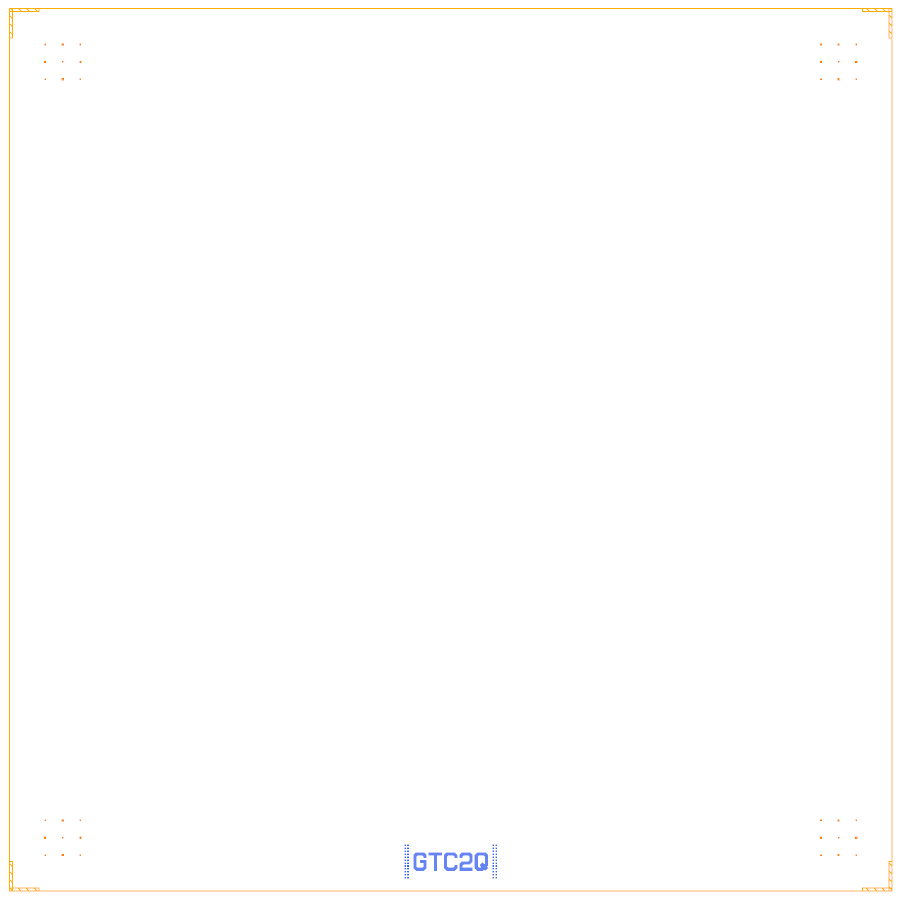

In [4]:
W = H = 7500                                     # PDK standard die
d = Designer("google_tc_cell", box=(0, 0, W, H), chip={"name_chip": "GTC2Q"}, live=LIVE)
snap(d, OUT / "google_tc_cell_die.png", size=(900, 900), width=320);

## 3 · Pads: the PDK pad rule

Seven Quantcore `BondPad`s: the feedline's two (west and east edges, at the feedline height `YF`), the two XY drive
pads (west and east, at the qubit row `Y0`) and the three Z pads on the south edge. The PDK puts the outer edge of
every pad's etch **`frame.pad_edge` = 100 µm from the die edge**: `edge="auto"` slides each pad perpendicular to
its nearest edge until that holds, keeping its position along the edge. `pads_md(d)` lists the distances.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| FL_in | `BondPad` | w | 100.0 | ✓ |
| FL_out | `BondPad` | e | 100.0 | ✓ |
| XY1 | `BondPad` | w | 100.0 | ✓ |
| XY2 | `BondPad` | e | 100.0 | ✓ |
| Z1 | `BondPad` | s | 100.0 | ✓ |
| ZC | `BondPad` | s | 100.0 | ✓ |
| Z2 | `BondPad` | s | 100.0 | ✓ |

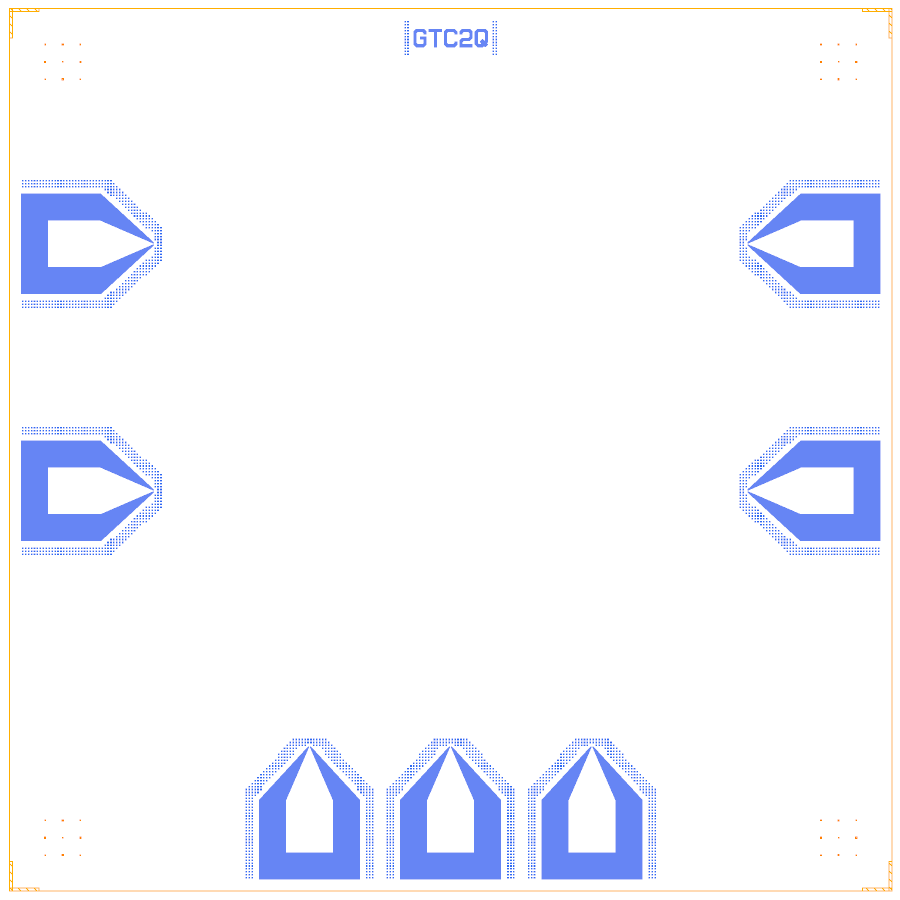

In [5]:
X0, Y0, YF = 3750, 3400, 5500                    # coupler centre, qubit row, feedline (before centring, step 6)
pad = lambda n, x, y, r: d.add(n, "BondPad", at=(x, y), rot=r, edge="auto")
P = {"FL_in": pad("FL_in", 1150, YF, -90), "FL_out": pad("FL_out", W - 1150, YF, 90),
     "XY1": pad("XY1", 1150, Y0, -90), "XY2": pad("XY2", W - 1150, Y0, 90),
     "Z1": pad("Z1", 2550, 1150, 0), "ZC": pad("ZC", X0, 1150, 0), "Z2": pad("Z2", W - 2550, 1150, 0)}
rebuild(d)
display(Markdown(pads_md(d)))
snap(d, OUT / "google_tc_cell_pads.png", size=(900, 900), width=320);

## 4 · Components: crosses, trilayer SQUIDs and the couplings

**The junctions.** Qubits and coupler each carry a Quantcore trilayer SQUID drawn for L_J = 6.1 nH at zero flux,
the low end of the PDK window (R_n ≈ 40 kΩ: the largest E_J, so the highest f_q per E_C). `trilayer_junction(...,
squid=True)` returns the cell parameters that draw it and the values the LOM uses.

The DRC's `pdk_rn` judges the device, the SQUID's two junctions in parallel: ≈ 40 kΩ (each junction ≈ 80 kΩ),
inside the window, so these SQUIDs raise no warning.

In [6]:
QJ_PARAMS, QJ = trilayer_junction("metal:TransmonCrossFL", lj_nH=6.1, squid=True)
CJ_PARAMS, CJ = trilayer_junction("metal:TransmonCrossFL", lj_nH=6.1, squid=True)
print("qubit / coupler SQUID (drawn, zero flux):", QJ, "→ parallel R_n",
      round(rn_from_lj(QJ["Lj_nH"]) / 1e3, 1), "kΩ; each junction", round(2 * rn_from_lj(QJ["Lj_nH"]) / 1e3, 1), "kΩ")

qubit / coupler SQUID (drawn, zero flux): {'Lj_nH': 6.0129, 'Cj_fF': 16.8} → parallel R_n 40.2 kΩ; each junction 80.4 kΩ


**The geometry** (µm). Qubit crosses 160 µm arms; a smaller coupler cross (70 µm arms) puts the coupler's maximum
frequency above the qubits. Arm tips face each other across a 100 µm gap. The readout claw wraps the qubit's north
arm tip; its fingers stop short of the east and west arms (`claw_length` < arm length, else the DRC's `pdk_claw`).

In [7]:
LQ, WQ, GQ = 160, 30, 30                         # qubit cross: arm length from the centre, arm width, gap
LC, WC, GC = 70, 20, 20                          # coupler cross (smaller: f_c,max above the qubits)
GAP = 100                                        # qubit arm tip ↔ coupler arm tip
S = LQ + GAP + LC                                # qubit ↔ coupler centre pitch
L_READ = {"R1": 6215, "R2": 6095}                # λ/4 lengths (claw → shorted hanger end), set for F_R with the LOM
K_LEN = 900                                      # hanger coupling length (κ ≈ 0.64 MHz)
CLAW = dict(connector_type="0", claw_length=130, ground_spacing=3, claw_width=30, claw_gap=4, connector_location="90")

cross = lambda name, x, L, w, g, pads, jp, j: d.add(name, "metal:TransmonCrossFL", at=(x, Y0), junction=j,
                                                   cross_length=L, cross_width=w, cross_gap=g,
                                                   connection_pads=pads, **jp)
q1 = cross("Q1", X0 - S, LQ, WQ, GQ, {"readout": CLAW}, QJ_PARAMS, QJ)
q2 = cross("Q2", X0 + S, LQ, WQ, GQ, {"readout": CLAW}, QJ_PARAMS, QJ)
tc = cross("TC", X0, LC, WC, GC, {}, CJ_PARAMS, CJ)                 # the coupler: a small Xmon with a SQUID
# XY drive ends: open CPW ends facing the qubits' outer arm tips (20 µm of ground between)
xy1 = d.add("XY1_end", "metal:OpenToGround", at=(X0 - S - LQ - GQ - 26, Y0), rot=0)
xy2 = d.add("XY2_end", "metal:OpenToGround", at=(X0 + S + LQ + GQ + 26, Y0), rot=180)
print(q1, tc, sep="\n")

<metal:TransmonCrossFL Q1 ports=['flux_line', 'readout', 'squid_a', 'squid_b']>
<metal:TransmonCrossFL TC ports=['flux_line', 'squid_a', 'squid_b']>


**The couplings no route carries.** The arm-tip capacitances (qubit ↔ coupler, end-on across 100 µm) and the direct
qubit ↔ qubit capacitance across the coupler (screened by it: the knob that sets the off point, Yan Eq. 4–5) are
rough coplanar-strip estimates, declared with `d.couple`. The Q3D job `core` (step 9) replaces them.

C(Q ↔ C) ≈ 2.35 fF, C(Q1 ↔ Q2) ≈ 0.282 fF


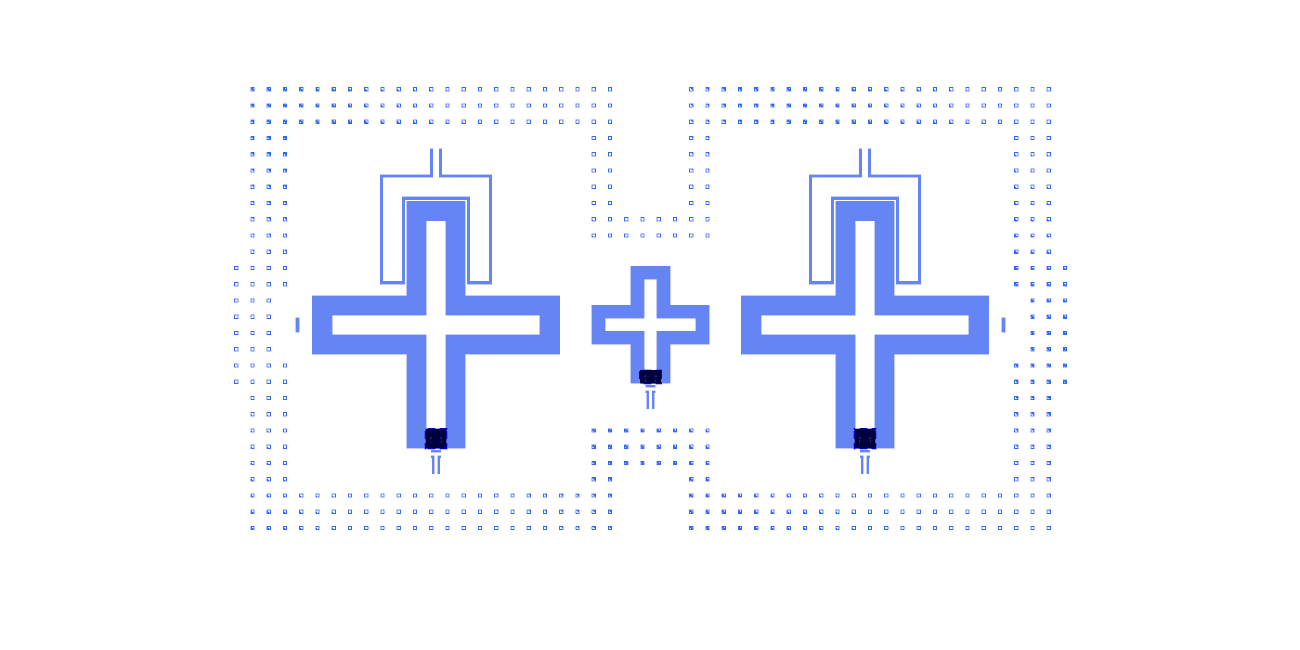

In [8]:
C_QC = round(est.coplanar_coupling(WQ, LQ, LC, GAP, EPS), 2)      # qubit arm tip ↔ coupler arm tip, end-on
C_QQ = round(est.coplanar_coupling(WQ, LQ, LQ, 2 * GAP + 2 * LC, EPS, screening=0.15), 3)
print(f"C(Q ↔ C) ≈ {C_QC} fF, C(Q1 ↔ Q2) ≈ {C_QQ} fF")
d.couple("Cg_Q1_TC", "Q1", "TC", C_fF=C_QC, note="Q1 east arm tip ↔ coupler west arm tip, 100 µm (CPS estimate)")
d.couple("Cg_TC_Q2", "TC", "Q2", C_fF=C_QC, note="coupler east arm tip ↔ Q2 west arm tip, 100 µm (CPS estimate)")
d.couple("Cg_Q1_Q2", "Q1", "Q2", C_fF=C_QQ, note="Q1 ↔ Q2 across the coupler (CPS, screening 0.15)")
snap(d, OUT / "google_tc_cell_components.png", box=(X0 - S - 600, Y0 - 500, X0 + S + 600, Y0 + 500),
     size=(1300, 650), width=560);

## 5 · Routes: feedline, readouts, XY and Z lines

- **Feedline:** a straight 10/6 µm CPW between the two feedline pads.
- **Readouts:** each λ/4 runs from the qubit's claw (open end) up and across to a **hanger** on the feedline: a
  900 µm coupled section beside the line, shorted at its end. `fl.hanger(near=(x, y), length=...)` gives that end spec: it centres the coupler at
  the feedline point nearest (x, y), so it stays put when the pads (and so the feedline's start) move;
  `meander=` sets the total length (from the LOM calibration for 4.58 / 4.66 GHz) and the router adds the meander on
  the vertical run.
- **XY lines:** straight from the XY pads to the open ends beside the qubits.
- **Z lines:** each cross's flux T-line (`flux_line`) to its south pad, with waypoints.

In [9]:
fl = d.route("FL", P["FL_in"].a, P["FL_out"].a)                      # straight feedline, 10/6 µm
for k, q, sgn in ((1, q1, -1), (2, q2, 1)):
    xc = X0 + sgn * 1150                                             # hanger centre
    xv = xc - K_LEN / 2                                              # the readout rises to the hanger start
    d.route(f"R{k}", q.readout, fl.hanger(near=(xc, YF), length=K_LEN, side="right", ground_gap=4, end="short"),
            meander=L_READ[f"R{k}"], r=50, nodes=[(X0 + sgn * S, Y0 + 450), (xv, Y0 + 450), (xv, YF - 300)])
d.route("XY1_line", P["XY1"].a, xy1.open)
d.route("XY2_line", P["XY2"].a, xy2.open)
d.route("Z1_line", q1.flux_line, P["Z1"].a, r=50, nodes=[(X0 - S, 2400), (2550, 2400)])
d.route("ZC_line", tc.flux_line, P["ZC"].a, r=50)
d.route("Z2_line", q2.flux_line, P["Z2"].a, r=50, nodes=[(X0 + S, 2400), (W - 2550, 2400)])
rebuild(d)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})

{'FL': 5050.0, 'R1': 6215.0, 'R2': 6095.0, 'XY1_line': 1979.0, 'XY2_line': 1979.0, 'Z1_line': 2773.6, 'ZC_line': 2046.5, 'Z2_line': 2773.6}


## 6 · PDK placement: centre the content

The PDK wants the content in the middle of the die. Laid out as above it sits 738 µm low: the feedline is only
2.1 mm above the qubit row, so the upper third of the die is empty. `center_in_die(d)` measures the bounding box of
every instance and route and shifts them all (positions, waypoints) to centre it. The three Z pads keep `edge="auto"`,
so they stay 100 µm from the south edge and their lines get longer; the feedline and XY pads slide up along the side
edges.

The box of everything is then ≈ 0.4 mm low, not zero: the Z pads cannot leave the south edge, and a second shift
would put the feedline pads into the corner marker areas. The qubits now sit 0.39 mm above the die centre with the
feedline above them, and the die is filled evenly. This run: shift (0, +737.5) µm, qubit row Y0 = 4137.5,
feedline YF = 6237.5; `pdk_report` then gives the content centre (0, −369) µm.

In [10]:
DX, DY = center_in_die(d)
X0, Y0, YF = X0 + DX, Y0 + DY, YF + DY           # the cell's reference points after the shift
print("shift applied (µm):", (DX, DY), "→ qubit row Y0 =", Y0, ", feedline YF =", YF)
rebuild(d)
display(Markdown(pads_md(d)))

shift applied (µm): (0.0, 737.5) → qubit row Y0 = 4137.5 , feedline YF = 6237.5


| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| FL_in | `BondPad` | w | 100.0 | ✓ |
| FL_out | `BondPad` | e | 100.0 | ✓ |
| XY1 | `BondPad` | w | 100.0 | ✓ |
| XY2 | `BondPad` | e | 100.0 | ✓ |
| Z1 | `BondPad` | s | 100.0 | ✓ |
| ZC | `BondPad` | s | 100.0 | ✓ |
| Z2 | `BondPad` | s | 100.0 | ✓ |

**Targets and FEM groups.** The targets are the source's (qubit idle frequency and α, the staggered readouts with
Sycamore's κ). Two sim groups define the FEM boxes: the Q–C–Q `core` with the XY ends (C-matrix: replaces the three
estimates and gives the XY drive capacitances) and `Q1_read`, Q1 with its readout. The layout is complete, so it is
saved here.

In [11]:
d.targets(Q1={"f_q_GHz": SRC["f_q_idle_GHz"], "alpha_MHz": SRC["alpha_MHz"]},
          Q2={"f_q_GHz": SRC["f_q_idle_GHz"], "alpha_MHz": SRC["alpha_MHz"]},
          R1={"f_GHz": F_R["R1"], "kappa_MHz": SRC["kappa_MHz"]}, R2={"f_GHz": F_R["R2"], "kappa_MHz": SRC["kappa_MHz"]})
d.sim_group("core", ["Q1", "TC", "Q2", "XY1_end", "XY2_end"], margin_um=60, analyses=["q3d_cmatrix"])
d.sim_group("Q1_read", ["Q1", "R1"], margin_um=60, analyses=["q3d_cmatrix", "eigenmode_epr"])
DESIGN = d.save(OUT / "google_tc_cell.json")
print(d, "→", DESIGN)

<Designer google_tc_cell: 12 instances, 8 routes, live=False> → examples\designs\google\google_tc_cell.json


## 7 · DRC

`d.drc()` checks connectivity and the PDK margins. Three kinds of finding:
- **errors** (shorts, routes through components, opens): none expected;
- **warnings**: the junction attachment points `squid_a` / `squid_b` of the three crosses (the cell draws the
  trilayer SQUID across the gap itself), not route ends;
- **PDK design warnings**: none expected (the SQUIDs' parallel R_n ≈ 40 kΩ is in the window, step 4; the f_q
  targets are in 4–8 GHz; every pad at 100 µm).

This run: **0 errors · 6 warnings (`dangling_port`) · 0 PDK design warnings**; the drawn SQUID is 6.01 nH, parallel
R_n 40.2 kΩ (each junction 80.4 kΩ).

`pdk_report(d)` sums up the PDK checks: cheese source, centring, junction types, design warnings.

In [12]:
rebuild(d)
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

**0 errors · 6 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 6 | Q1.squid_a is not connected (no route or snap) |

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, -369) µm |
| junction types | Quantcore Squid × 3 |
| PDK design warnings | 0 (none) |

## 8 · Netlist and LOM

`d.lom()` maps every component's ports to circuit nodes:
- `TransmonCrossFL` → a grounded island with its SQUID (the drawn trilayer L_J / C_J), a node for the readout claw,
  the flux line as a control;
- each claw → hanger route → a λ/4 `TLres` with a hanger κ into the feedline `FL` (one conductor between the two
  50 Ω pads);
- the XY ends → 50 Ω drive ports ending open;
- the three `d.couple` capacitances → Q1–TC, TC–Q2 and Q1–Q2;
- the Z-line pads drop out: the flux T-line shorts to ground.

In [13]:
lb = d.lom()
show_netlist(lb)

**9 nodes · 21 branches · 3 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `FL` | `FL`, `FL_in.pad`, `FL_out.pad` |
| `XY1_end.end` | `XY1.pad`, `XY1_end.end` |
| `XY2_end.end` | `XY2.pad`, `XY2_end.end` |
| `Q1` | `Q1.island` |
| `Q1.readout` | `Q1.readout` |
| `Q2` | `Q2.island` |
| `Q2.readout` | `Q2.readout` |
| `TC` | `TC.island` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_FL_in` | R | `FL` – `gnd` | 50 Ω |
| `Port_FL_out` | R | `FL` – `gnd` | 50 Ω |
| `Port_XY1` | R | `XY1_end.end` – `gnd` | 50 Ω |
| `Port_XY2` | R | `XY2_end.end` – `gnd` | 50 Ω |
| `C_Q1` | C | `Q1` – `gnd` | 67.9 fF |
| `J_Q1` | SQUID | `Q1` – `gnd` | Lj 6.01 nH, Cj 16.8 fF |
| `Cg_Q1_readout` | C | `Q1` – `Q1.readout` | 4 fF |
| `Cc_Q1_readout` | C | `Q1.readout` – `gnd` | 104 fF |
| `C_Q2` | C | `Q2` – `gnd` | 67.9 fF |
| `J_Q2` | SQUID | `Q2` – `gnd` | Lj 6.01 nH, Cj 16.8 fF |
| `Cg_Q2_readout` | C | `Q2` – `Q2.readout` | 4 fF |
| `Cc_Q2_readout` | C | `Q2.readout` – `gnd` | 104 fF |
| `C_TC` | C | `TC` – `gnd` | 29 fF |
| `J_TC` | SQUID | `TC` – `gnd` | Lj 6.01 nH, Cj 16.8 fF |
| `C_Cg_Q1_TC` | C | `Q1` – `TC` | 2.35 fF |
| `C_Cg_TC_Q2` | C | `TC` – `Q2` | 2.35 fF |
| `C_Cg_Q1_Q2` | C | `Q1` – `Q2` | 0.282 fF |
| `R1` | TLres | `Q1.readout` – `gnd` | lambda/4, 6215 µm, 5.070 GHz |
| `K_R1` | HANGER | `Q1.readout` – `FL` | κ 1.08 MHz (L 900 µm) |
| `R2` | TLres | `Q2.readout` – `gnd` | lambda/4, 6095 µm, 5.170 GHz |
| `K_R2` | HANGER | `Q2.readout` – `FL` | κ 1.14 MHz (L 900 µm) |

| control | kind | target | line | length (µm) |
|---|---|---|---|---|
| `Z1_line` | flux_bias | `J_Q1` | `Z1_line` | 3511 |
| `ZC_line` | flux_bias | `J_TC` | `ZC_line` | 2784 |
| `Z2_line` | flux_bias | `J_Q2` | `Z2_line` | 3511 |

**Unconnected ports:** none

**Builder notes:**

- Port_Z1: both ends on gnd after merging conductors (dropped)
- Port_ZC: both ends on gnd after merging conductors (dropped)
- Port_Z2: both ends on gnd after merging conductors (dropped)

## 9 · LOM simulation

**(a) Qubit + readout pairs** (QuTiP dressed values; targets in brackets). The feedline is a 25 Ω load outside the
selection; the coupler is not in these groups, so the qubits sit ≈ 0.1 GHz above their value in the full cell (c).
The λ/4 lengths were calibrated before the Nb film's kinetic inductance (PDK `kinetic`) entered the LOM;
with it every line is ≈ 1.6 % slower, so f_r lands ≈ 75 MHz below its target. Flagged, not retuned (values are not
the point of the rebuild). This run: f_q 6.6675 GHz, α −236.5 MHz; R1 4.5054 / R2 4.5846 GHz; κ 0.671 /
0.705 MHz; χ −0.177 / −0.202 MHz.

In [14]:
read = {"Q1+R1": ["Q1", "R1", "FL"], "Q2+R2": ["Q2", "R2", "FL"]}
results = simulate_groups(d, read)
display(Markdown(groups_md(results, d.data["targets"])))
display(Markdown(f"Dispersive-shift target from Sycamore's g = {SRC['g_qr_MHz']} MHz: χ ≈ {CHI_T:.2f} MHz"))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q1+R1 | Q1 | 6.6675 (6.661) | -236.5 (-208) | R1 | 4.5054 (4.58) | 0.671 (0.64) | -0.177 |
| Q2+R2 | Q2 | 6.6676 (6.661) | -236.5 (-208) | R2 | 4.5846 (4.66) | 0.705 (0.64) | -0.202 |

Dispersive-shift target from Sycamore's g = 72.3 MHz: χ ≈ -0.58 MHz

**(b) Coupler sweep: g̃ and ZZ against the coupler frequency.** The coupler's SQUID L_J is stepped from its drawn
zero-flux value (6.0 nH, f_c,max) upwards — L_J(Φ) = L_J0/|cos πΦ|, so each row is a flux bias Φ. With the two
(identical) qubits degenerate, the dressed splitting of their levels is 2|g̃|; the sign is that of Yan's Eq. 5
evaluated on the same LOM capacitances (listed too: Eq. 5 is perturbative, the LOM splitting is the full circuit,
and they part where the coupler comes within a few hundred MHz of the qubits). For ZZ, Q2 is detuned by its L_J
(`DETUNE_LJ`) and the static ZZ of the detuned pair is read from the dressed levels.

This run: g̃ goes from +5.0 MHz at f_c,max (8.765 GHz) through 0 at f_c ≈ 7.772 GHz (L_J,c 7.56 nH, Φ ≈ 0.208 Φ0)
to −35.7 MHz at 6.868 GHz; Yan's Eq. 5 follows the LOM splitting within ≈ 0.4 MHz down to |g̃| ≈ 3 MHz and parts
from it below f_c ≈ 7.3 GHz. The detuned pair's ZZ is −89 kHz near the off point and −10 MHz at the bottom.

| L_J,c (nH) | Φ/Φ0 | f_c (GHz) | α_c (MHz) | f_q1 (GHz) | f_q2 (GHz) | 2·abs(g̃) (MHz) | g̃ (MHz) | g̃ Yan Eq. 5 (MHz) | ZZ (kHz), q2 detuned |
|---|---|---|---|---|---|---|---|---|---|
| 6.00 | 0.000 | 8.7653 | -423.9 | 6.5671 | 6.5771 | 10 | 5.01 | 5.1 | -199.8 |
| 6.25 | 0.090 | 8.5810 | -423.8 | 6.5671 | 6.5760 | 8.93 | 4.47 | 4.57 | -177.1 |
| 6.50 | 0.126 | 8.4077 | -423.3 | 6.5671 | 6.5748 | 7.7 | 3.85 | 3.98 | -154.6 |
| 6.75 | 0.151 | 8.2443 | -422.4 | 6.5671 | 6.5734 | 6.3 | 3.15 | 3.3 | -133 |
| 7.00 | 0.172 | 8.0900 | -420.8 | 6.5671 | 6.5718 | 4.7 | 2.35 | 2.53 | -113.5 |
| 7.25 | 0.190 | 7.9441 | -418.2 | 6.5671 | 6.5699 | 2.84 | 1.42 | 1.64 | -97.93 |
| 7.50 | 0.205 | 7.8059 | -414.3 | 6.5671 | 6.5678 | 0.664 | 0.332 | 0.614 | -89.11 |
| 7.75 | 0.218 | 7.6750 | -408.5 | 6.5671 | 6.5652 | 1.91 | -0.955 | -0.596 | -91.98 |
| 8.00 | 0.230 | 7.5509 | -399.7 | 6.5621 | 6.5671 | 5 | -2.5 | -2.03 | -115 |
| 8.50 | 0.251 | 7.3219 | -367.1 | 6.5536 | 6.5671 | 13.5 | -6.73 | -5.87 | -295.8 |
| 9.00 | 0.268 | 7.1183 | -301.9 | 6.5399 | 6.5671 | 27.2 | -13.6 | -11.7 | -1029 |
| 9.25 | 0.275 | 7.0266 | -256.4 | 6.5296 | 6.5671 | 37.5 | -18.8 | -15.8 | -2057 |
| 9.50 | 0.282 | 6.9427 | -206.9 | 6.5154 | 6.5671 | 51.7 | -25.9 | -20.9 | -4397 |
| 9.75 | 0.289 | 6.8683 | -159 | 6.4956 | 6.5671 | 71.5 | -35.7 | -26.9 | -1.029e+04 |

ZZ column: Q2 at 6.121 GHz (L_J 6.9 nH), Q1 at 6.567 GHz.

**Off point:** g̃ = 0 at f_c ≈ 7.772 GHz (L_J,c ≈ 7.56 nH, Φ ≈ 0.208 Φ0)

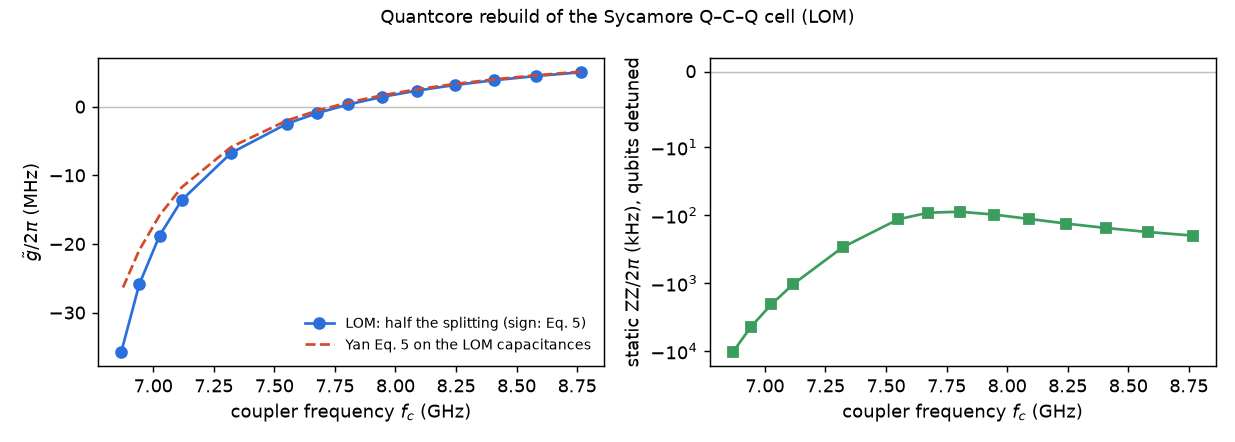

WindowsPath('examples/designs/google/google_tc_cell_sweep.png')

In [15]:
LJ_C = [6.0, 6.25, 6.5, 6.75, 7.0, 7.25, 7.5, 7.75, 8.0, 8.5, 9.0, 9.25, 9.5, 9.75]
DETUNE_LJ = 6.9                                  # Q2's L_J for the ZZ column (≈ 0.4 GHz below Q1)
sweep = coupler_sweep(d, ["Q1", "TC", "Q2"], "Q1", "Q2", "TC", LJ_C, detune_lj=DETUNE_LJ)
display(Markdown(coupler_sweep_md(sweep)))
display(Markdown(f"ZZ column: Q2 at {sweep[0]['f_q2_detuned_GHz']:.3f} GHz (L_J {DETUNE_LJ} nH), "
                 f"Q1 at {sweep[0]['f_q1_GHz']:.3f} GHz."))
off = off_point(sweep)
display(Markdown(f"**Off point:** g̃ = 0 at f_c ≈ {off['f_c_GHz']:.3f} GHz (L_J,c ≈ {off['lj_nH']:.2f} nH, "
                 f"Φ ≈ {off['flux_phi0']:.3f} Φ0)" if off else "**Off point:** not inside the sweep"))
plot_coupler_sweep(sweep, OUT / "google_tc_cell_sweep.png", title="Quantcore rebuild of the Sycamore Q–C–Q cell (LOM)")

**(c) The whole cell at the off point and at the "on" point** (Q1, R1, TC, Q2, R2 and the feedline together, Q2
detuned as in the ZZ column): QuTiP dressed values, so the qubit frequencies include the coupler's pull, and the
static ZZ at the idle (off) and gate (on) biases. The junction values are changed in the LOM only (the drawing and
the saved design keep the design values).

This run: at the off point (7.56 nH) Q1 sits at 6.566 GHz and the detuned Q2 at 6.118 GHz, α ≈ −193 MHz, the static
ZZ(Q1–Q2) −82 kHz; at the "on" bias (9.25 nH, g̃ ≈ −18.8 MHz) ZZ(Q1–Q2) is −1.83 MHz.

In [16]:
on = min(sweep, key=lambda r: abs(r["g_MHz"] - SRC["g_on_MHz"]))
cell = {}
d["Q2"].spec["junction"] = {**QJ, "Lj_nH": DETUNE_LJ}            # detuned pair (LOM only, the drawing is unchanged)
for label, lj in (("off", off["lj_nH"] if off else LJ_C[0]), ("on", on["lj_nH"])):
    d["TC"].spec["junction"] = {**CJ, "Lj_nH": round(lj, 4)}    # the coupler at this bias (LOM only)
    cell.update(simulate_groups(d, {f"cell, coupler {label} ({lj:.2f} nH)": ["Q1", "R1", "TC", "Q2", "R2", "FL"]},
                                max_modes=5))
d["Q2"].spec["junction"], d["TC"].spec["junction"] = dict(QJ), dict(CJ)   # back to the design values
display(Markdown(groups_md(cell)))
display(Markdown(zz_md(cell)))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| cell, coupler off (7.56 nH) | Q2 | 6.1183 | -193.7 | R1 | 4.5054 | 0.671 | -0.175 |
|  | Q1 | 6.566 | -193 | R2 | 4.5843 | 0.705 | -0.353 |
|  | TC | 7.7741 | -329.5 | – | – | – | – |
| cell, coupler on (9.25 nH) | Q2 | 6.112 | -189.8 | R1 | 4.5054 | 0.671 | -0.164 |
|  | Q1 | 6.5468 | -178.1 | R2 | 4.5843 | 0.705 | -0.349 |
|  | TC | 7.0172 | -236.6 | – | – | – | – |

| group | pair | ZZ (kHz) | neighbours | hybridised |
|---|---|---|---|---|
| cell, coupler off (7.56 nH) | Q1-Q2 | -82.45 | yes | no |
| cell, coupler off (7.56 nH) | Q2-TC | -7047 | yes | no |
| cell, coupler off (7.56 nH) | Q1-TC | -1.52e+04 | yes | no |
| cell, coupler on (9.25 nH) | Q1-Q2 | -1826 | yes | no |
| cell, coupler on (9.25 nH) | Q2-TC | -2.702e+04 | yes | no |
| cell, coupler on (9.25 nH) | Q1-TC | -1.107e+05 | yes | no |

## 10 · FEM: send the job

Two sim groups, three jobs: a Q3D C-matrix job for the Q–C–Q `core` with the two XY ends (the box cuts the readouts
and Z lines once), and for `Q1_read` a C-matrix and an eigenmode job with its readout (lines leaving the box end in
50 Ω). Simulation builds draw the junctions as Metal's lumped line (`junction_type="Sim"`) and never carry cheese.
Exporting again replaces a job folder, results included.

`RUN_FEM = False` only exports. With `RUN_FEM = True` and AEDT 2024 R1 (or newer) on this machine, `send_fem_jobs`
solves each job in a **new batch, non-graphical AEDT** (`solve_job`); an AEDT window you have open is never touched. Elsewhere:
`qcc hfss solve build/jobs/<job>`.

In [17]:
RUN_FEM = False                                  # True: solve the jobs now in a new batch AEDT (2024 R1 or newer)
jobs = export_sims(DESIGN, ["core", "Q1_read"])
jobs_eig = export_sims(DESIGN, ["Q1_read"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))
if RUN_FEM:
    send_fem_jobs(DESIGN, ["core", "Q1_read"], run=True)   # each group's own analyses

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| core | `build/jobs/google_tc_cell_core_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · junction · `TC.junction`<br>3 · junction · `Q2.junction`<br>4 · edge · `XY1_line`<br>5 · edge · `XY2_line`<br>6 · edge · `Z1_line`<br>7 · edge · `Z2_line`<br>8 · edge · `ZC_line` | `Q1.island`, `TC.island`, `Q2.island`, `XY1_line`, `XY2_line` |
| Q1_read | `build/jobs/google_tc_cell_Q1_read_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · waveguide · `Q1.readout`<br>3 · edge · `XY1_line`<br>4 · edge · `Z1_line` | `Q1.island`, `XY1_line` |
| Q1_read | `build/jobs/google_tc_cell_Q1_read_eigenmode_epr` | 1 · junction · `Q1.junction`<br>2 · edge_lumped · `FL`<br>3 · edge_lumped · `FL`<br>4 · edge_lumped · `XY1_line`<br>5 · edge_lumped · `Z1_line` | `Q1.island`, `FL`, `FL#2`, `XY1_line`, `Z1_line` |

## 11 · Bring the results back

When a job has results (`build/jobs/<job>/results/results.json`), `fill(model, design, job)` puts the extracted
capacitances into the LOM by net name (`Q1.island`, `TC.island`, `Q2.island`, the XY lines, the claw) next to the
estimates: the three `d.couple` values are replaced by the C-matrix, and steps 9 (b)–(c) can be run again on them.
Until a solve has run, the cell says what would appear.

In [18]:
filled, md = fem_back(lb.model, DESIGN, {**{f"{g} · q3d": v for g, v in jobs.items()},
                                         **{f"{g} · eigenmode": v for g, v in jobs_eig.items()}})
display(Markdown(md))

No FEM results yet for core · q3d, Q1_read · q3d, Q1_read · eigenmode: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 12 · Iterate: change one property and re-simulate

The readout's χ comes out ≈ −0.2 MHz against Sycamore's ≈ −0.58 MHz (g ≈ 45 vs 72 MHz). The knob is the claw: here
Q1's `claw_length` goes from 130 to 100 µm, which lowers its coupling capacitance, so |χ| drops further and the
readout moves up a little. The other direction (a longer claw) would reach the cross's side arms (`pdk_claw`): the
cross arm would have to grow too. `design_copy` opens a second, non-live Designer on the saved design; the design
file stays as it is. This run: χ −0.177 → −0.134 MHz, f_r 4.505 → 4.564 GHz, f_q 6.6675 → 6.6925 GHz.

In [19]:
d2 = design_copy(DESIGN)
d2["Q1"].set(connection_pads={"readout": {**CLAW, "claw_length": 100}})
res2 = simulate_groups(d2, {"Q1+R1": read["Q1+R1"]})
display(Markdown(params_delta_md({"Q1+R1": results["Q1+R1"]}, res2)))

| parameter | before | after | Δ |
|---|---|---|---|
| `Q1+R1: R1.f_GHz` | 4.5054 | 4.564 | +0.05858 |
| `Q1+R1: R1.kappa_MHz` | 0.67104 | 0.70669 | +0.03565 |
| `Q1+R1: R1.chi_MHz` | -0.17732 | -0.13386 | +0.04346 |
| `Q1+R1: Q1.f_q_GHz` | 6.6675 | 6.6925 | +0.02498 |
| `Q1+R1: Q1.alpha_MHz` | -236.54 | -238.53 | -1.993 |

## 13 · Build and export

- **Design file:** `d.save(...)` wrote `examples/designs/google/google_tc_cell.json` (step 6): cells, positions,
  routes, couplings, targets and sim groups; `Designer.load` reopens it.
- **Fab mask:** `export_fab` writes only the PDK fab layers (negative mask), with corner rounding and the cheese the
  build drew (the PDK band: no original cheese exists). The table lists each fab layer (this
  run: 8045 holes).
- **Simulation export options:** `build_simulation(design, group, analysis, airbridges=True)` keeps airbridges in a
  FEM export (this cell has none); cheese is never exported.
- **The same from the command line:** `qcc build examples/designs/google/google_tc_cell.json` (layout + sidecar),
  `qcc design drc …`, `qcc mask …` (fab file), `qcc sim build … -g core -a q3d_cmatrix`,
  `qcc hfss solve build/jobs/<job>`.

In [20]:
rebuild(d)
display(Markdown(fab_layers_md(d, cheese=True, rounding=True)))

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 8064 |
| 2/0 | JJ_STRAIGHT | 3 |
| 3/0 | M3 | 8052 |
| 4/0 | JJ_BENT | 3 |
| 50/0 | HSQ | 12 |
| 51/0 | SPACER_1 | 12 |
| 52/0 | SPACER_2 | 12 |
| 53/0 | SPACER_3 | 12 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 8045 holes on the mask.

→ `build/google_tc_cell_fab.oas`

## 14 · Snapshots

The full die (PDK frame, QCT device ID); the Q–C–Q core (claws round the north arms, short of the side arms; the small
coupler cross between the qubits); the coupler's SQUID (the trilayer cell across the gap, the flux T-line below); the
Q1 hanger on the feedline; and the fab mask round the core (the PDK band's 5 µm holes along the 3/0 keep-outs, on 1/0
and 3/0, the junction layers).

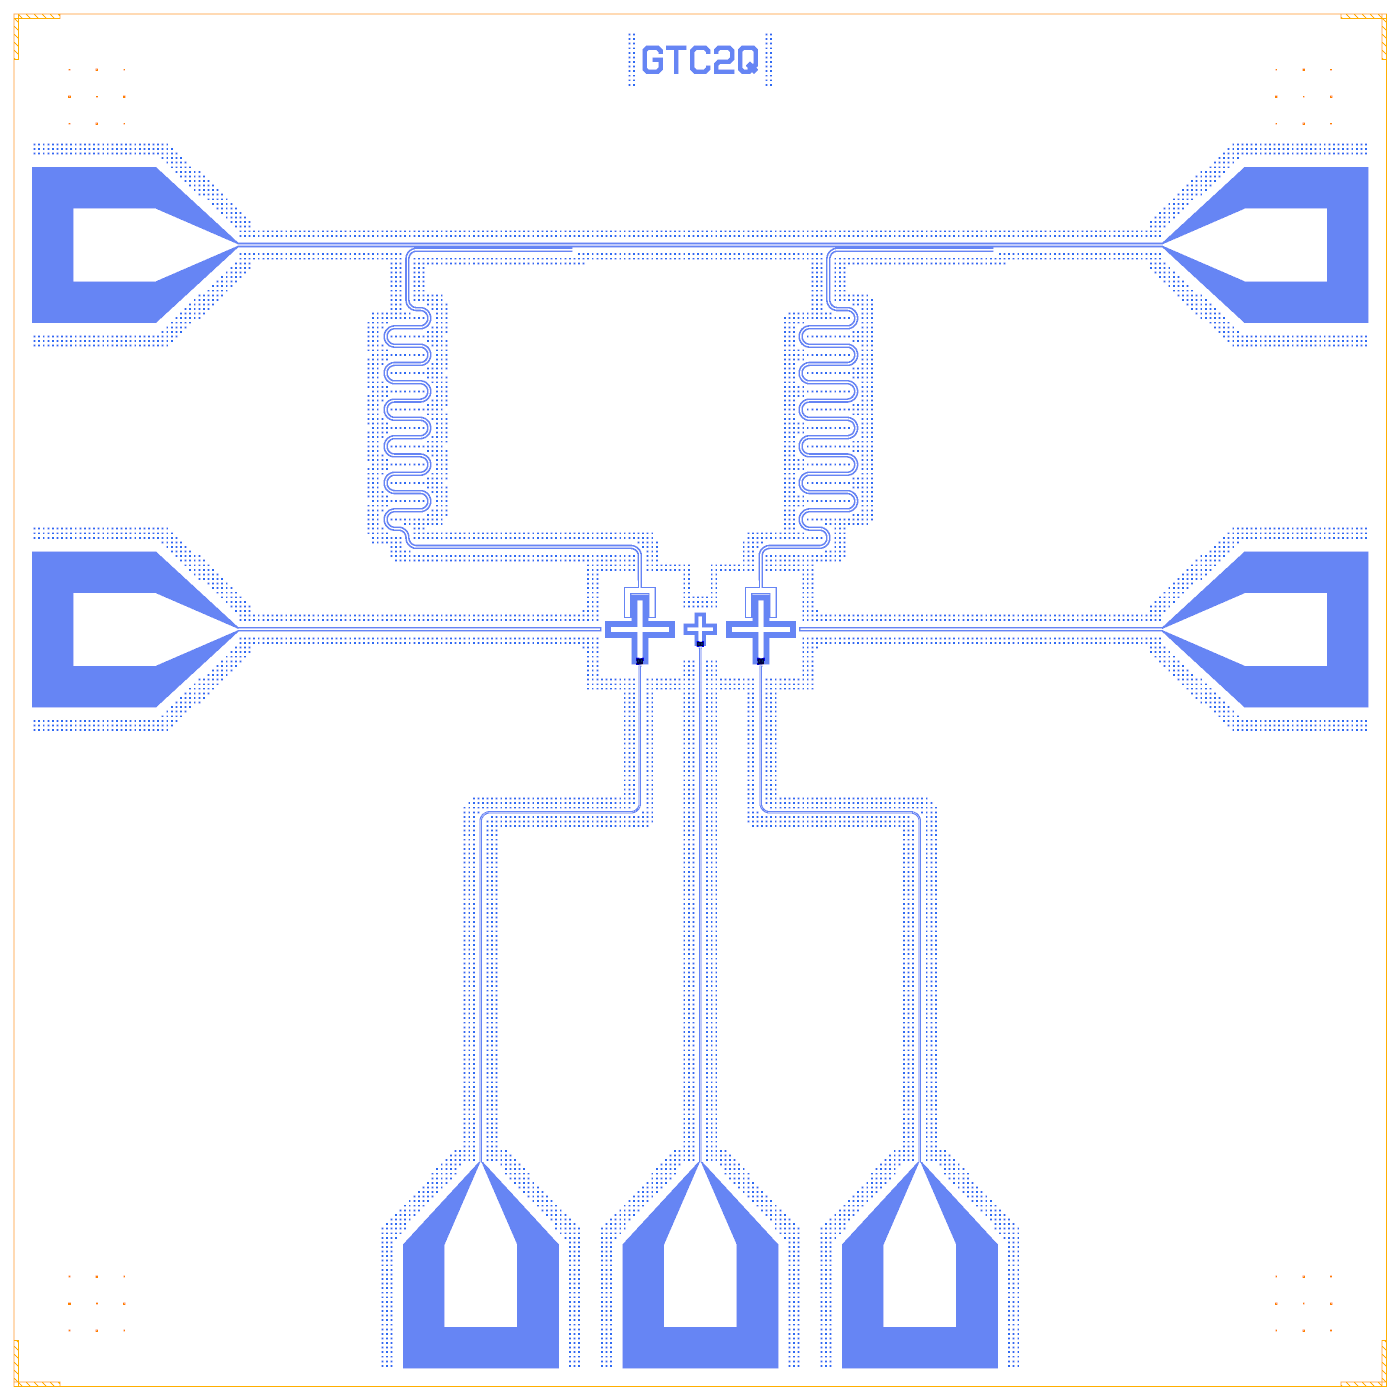

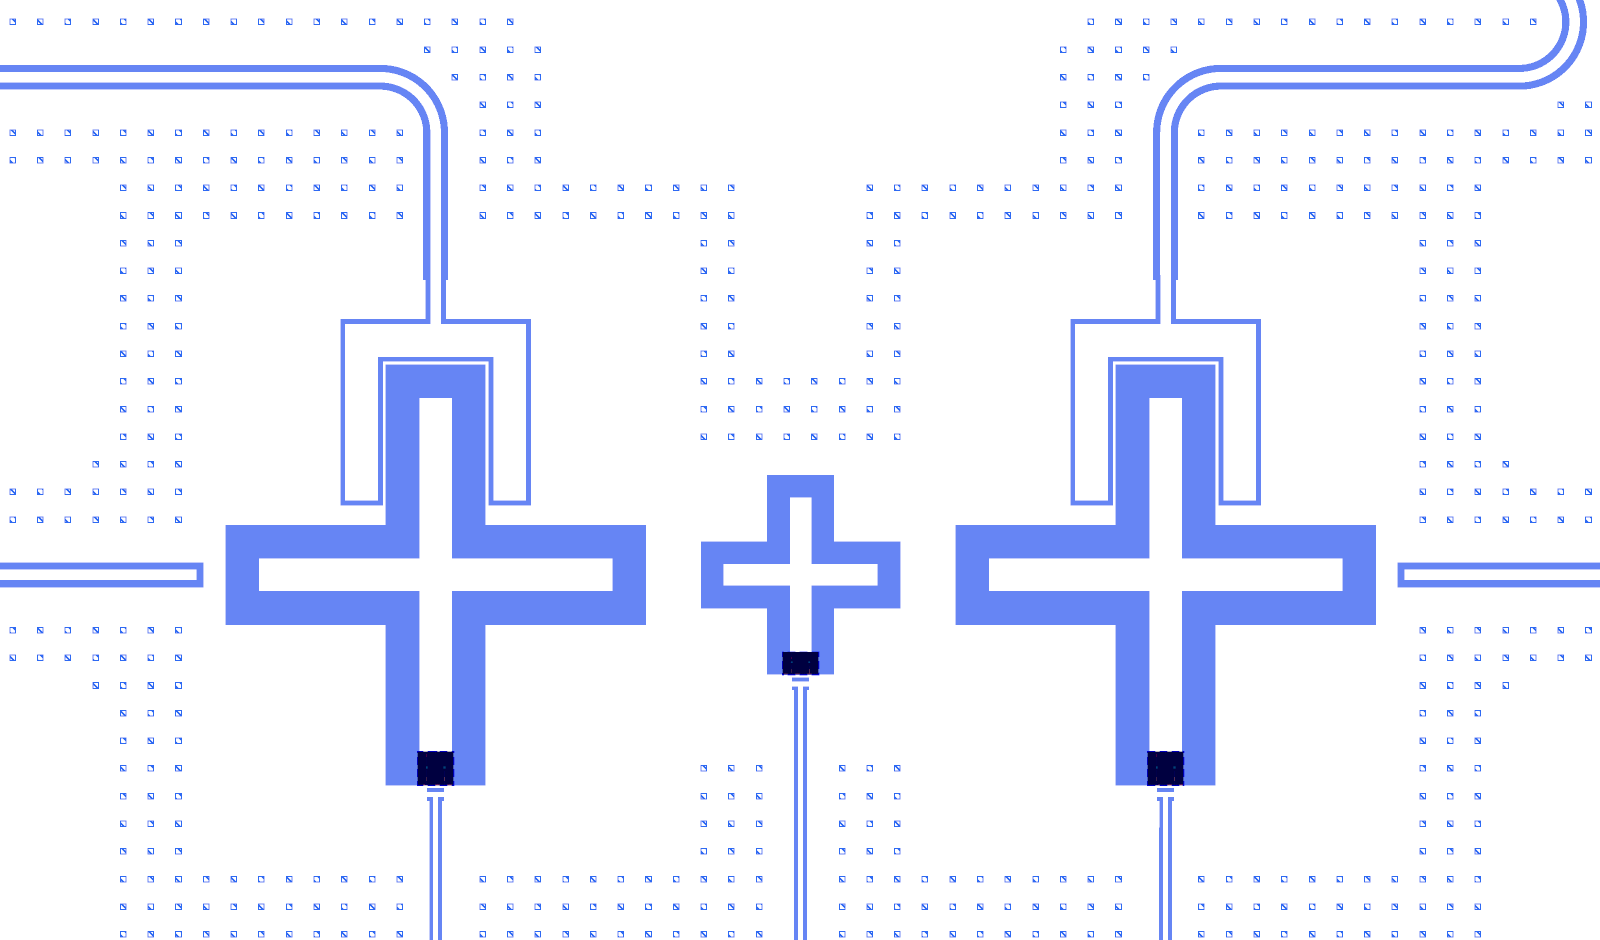

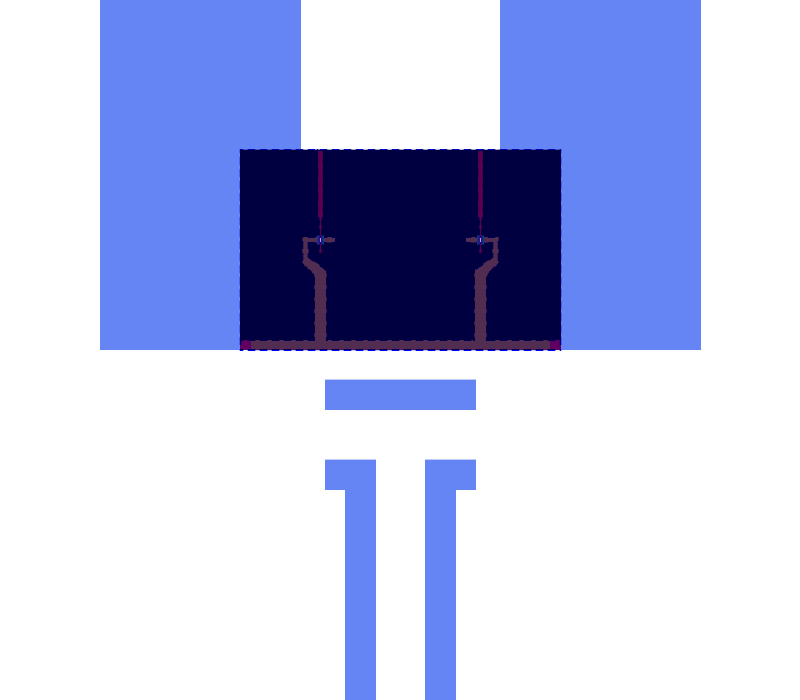

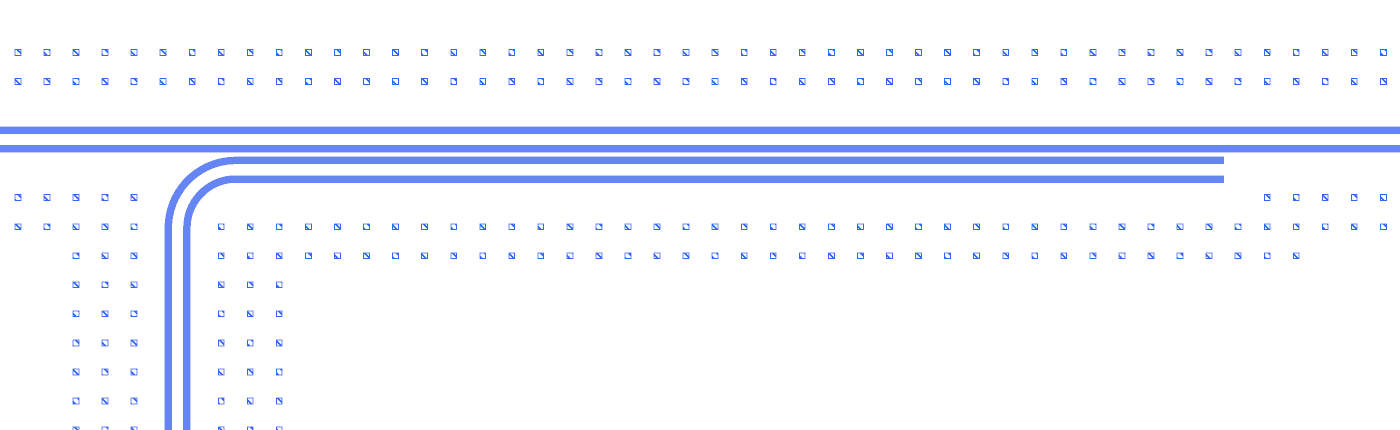

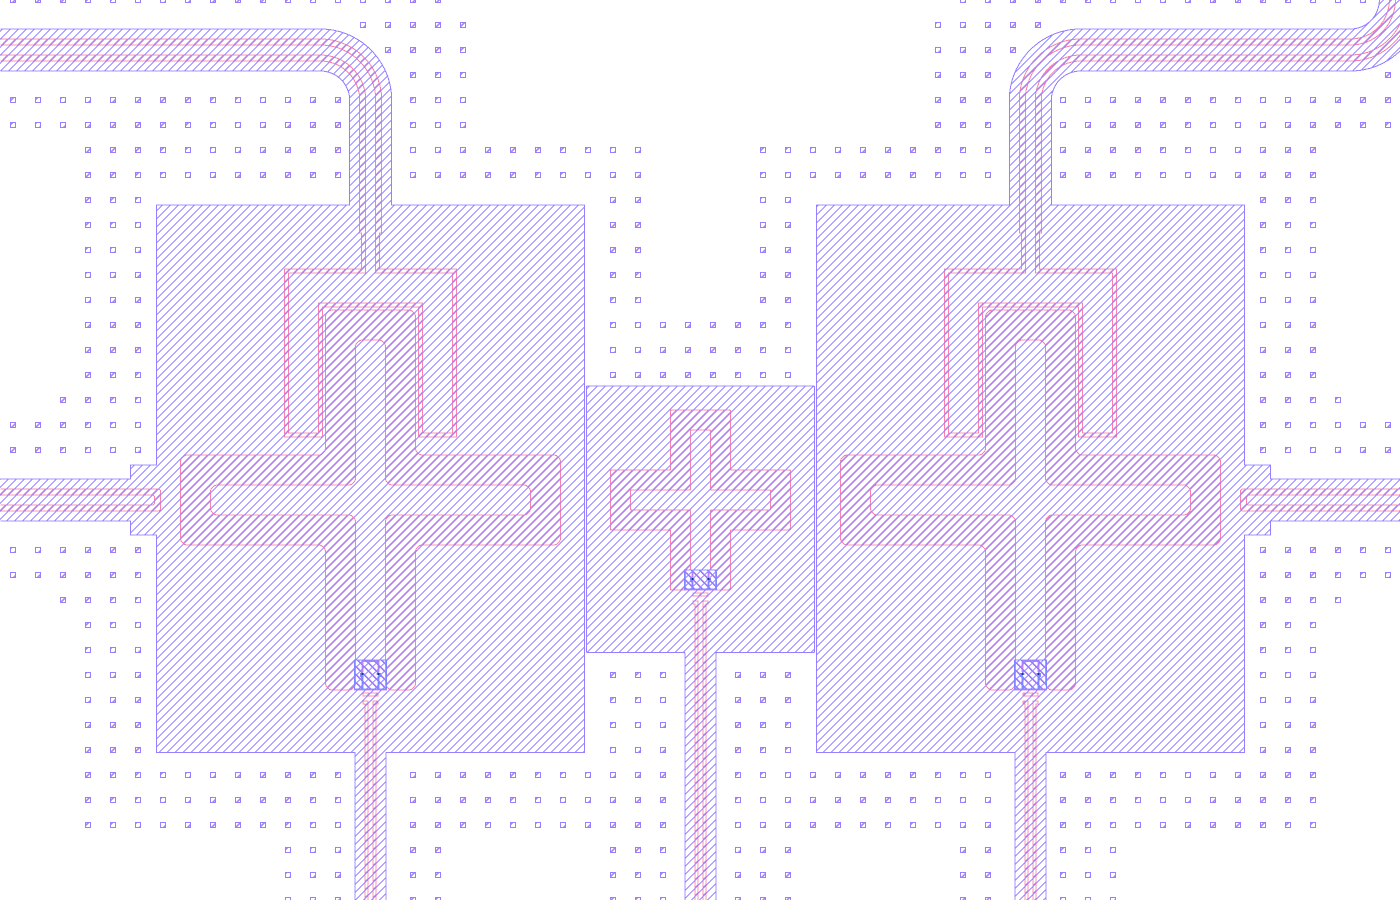

In [21]:
snap(d, OUT / "google_tc_cell.png", size=(1400, 1400))
snap(d, OUT / "google_tc_cell_core.png", box=(X0 - S - 260, Y0 - 330, X0 + S + 260, Y0 + 520),
     size=(1600, 940), width=640)
snap(d, OUT / "google_tc_cell_squid.png", box=(X0 - 40, Y0 - 125, X0 + 40, Y0 - 55), size=(800, 700), width=320)
snap(d, OUT / "google_tc_cell_hanger.png", box=(X0 - 1150 - 600, YF - 250, X0 - 1150 + 600, YF + 120),
     size=(1400, 430), width=640)
snap_file(Path("build") / "google_tc_cell_fab.oas", OUT / "google_tc_cell_cheese.png",
          box=(X0 - S - 300, Y0 - 400, X0 + S + 300, Y0 + 500), size=(1400, 900), width=560);

## 15 · Summary

- **Matches the source:** the Q–C–Q architecture, the off point inside the coupler range (g̃ from +5 MHz through 0
  to ≈ −36 MHz, the "on" value −20 MHz reachable), f_q at Sycamore's idle, κ at Sycamore's value; the readouts
  ≈ 1.6 % below their targets (Nb kinetic inductance now in the LOM, step 9 a).
- **Changed by the PDK:** trilayer SQUIDs at R_n ≈ 40 kΩ (α −237 MHz alone, ≈ −193 MHz in the cell, vs −208 MHz);
  the 7.5 mm die and frame; pads 100 µm from the edges; the content shifted up 738 µm to fill the die; the PDK band
  cheese (no original exists).
- **Open PDK design warnings:** none (the SQUIDs' parallel R_n 40.2 kΩ is in the window). The FEM jobs are exported,
  not solved (`RUN_FEM = False`).
- **Known limits:** the readout g is ≈ 45 MHz (claw shorter than the arm); the three coupling capacitances are CPS
  estimates until the `core` Q3D job has run.